In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

digits = load_digits()
X, y = digits.images / 16, digits.target

Xtr, Xrest, ytr, yrest = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y)

Xva, Xte, yva, yte = train_test_split(
    Xrest, yrest, test_size=0.5, random_state=42, stratify=yrest)

print(len(Xtr), len(Xva), len(Xte))



1078 359 360


In [2]:
from torch.utils.data import TensorDataset, DataLoader

A = torch.tensor(Xtr, dtype=torch.float32)[:, None]
V = torch.tensor(Xva, dtype=torch.float32)[:, None]
E = torch.tensor(Xte, dtype=torch.float32)[:, None]

ya, yv, ye = torch.tensor(ytr), torch.tensor(yva), torch.tensor(yte)
torch.manual_seed(42)

loader = DataLoader(TensorDataset(A, ya), batch_size=64, shuffle=True)

In [3]:
def make_cnn(bn=False):
    c1 = nn.Conv2d(1, 16, 3, padding=1)
    c2 = nn.Conv2d(16, 32, 3, padding=1)
    if bn:
        return nn.Sequential(
            c1, nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            c2, nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(), nn.Linear(128, 10))
    return nn.Sequential(
        c1, nn.ReLU(), nn.MaxPool2d(2),
        c2, nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(128, 10))

In [4]:
def acc(m, x, y):
    m.eval()
    with torch.no_grad():
        return (m(x).argmax(1) == y).float().mean().item()

def train(model, epochs=30, tf=None):
    opt = torch.optim.Adam(model.parameters(), lr=0.003)
    hist = []
    for _ in range(epochs):
        model.train()
        for xb, yb in loader:
            if tf: xb = tf(xb)
            loss = F.cross_entropy(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        hist.append(acc(model, V, yv))
    return hist

In [5]:
torch.manual_seed(0)
model = make_cnn()
hist = train(model)
print([round(a, 3) for a in hist[4::5]])
print(round(acc(model, A, ya), 4), round(acc(model, V, yv), 4))

[0.9, 0.95, 0.967, 0.972, 0.969, 0.975]
0.9991 0.9749


In [6]:
pred = model(V).argmax(1)
cm = torch.zeros(10, 10, dtype=torch.long)

for t, p in zip(yv, pred):
    cm[t, p] += 1
print(cm.diag().sum().item(), len(yv))
print(cm)


350 359
tensor([[36,  0,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 0, 36,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 0,  0, 34,  0,  0,  0,  0,  2,  0,  0],
        [ 0,  0,  0, 36,  0,  0,  0,  0,  0,  0],
        [ 0,  0,  0,  0, 35,  0,  1,  0,  0,  0],
        [ 0,  0,  0,  0,  0, 35,  0,  0,  0,  1],
        [ 0,  0,  0,  0,  0,  0, 36,  0,  0,  0],
        [ 0,  0,  0,  1,  0,  0,  0, 35,  0,  0],
        [ 0,  3,  0,  0,  0,  0,  0,  0, 32,  0],
        [ 0,  0,  0,  0,  0,  0,  0,  0,  1, 35]])


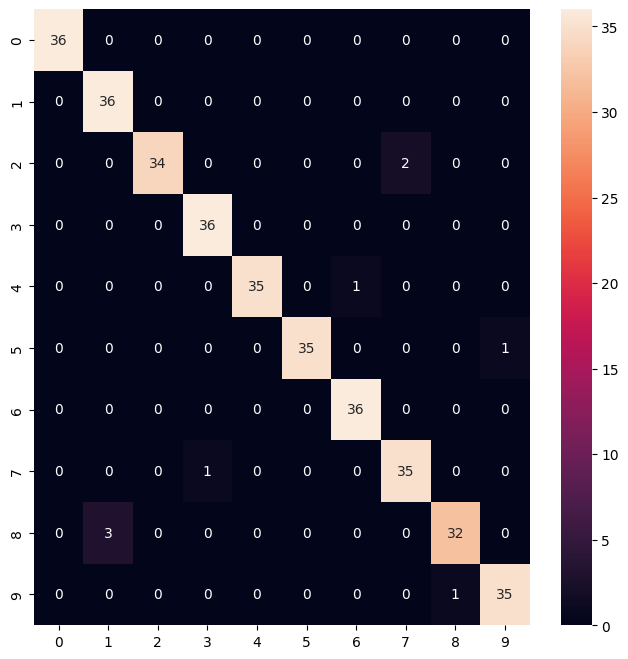

tensor([[36,  0,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 0, 36,  0,  0,  0,  0,  0,  0,  0,  0],
        [ 0,  0, 34,  0,  0,  0,  0,  2,  0,  0],
        [ 0,  0,  0, 36,  0,  0,  0,  0,  0,  0],
        [ 0,  0,  0,  0, 35,  0,  1,  0,  0,  0],
        [ 0,  0,  0,  0,  0, 35,  0,  0,  0,  1],
        [ 0,  0,  0,  0,  0,  0, 36,  0,  0,  0],
        [ 0,  0,  0,  1,  0,  0,  0, 35,  0,  0],
        [ 0,  3,  0,  0,  0,  0,  0,  0, 32,  0],
        [ 0,  0,  0,  0,  0,  0,  0,  0,  1, 35]])

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
sns.heatmap(cm, annot=True)
plt.show()
cm

In [8]:
for bn in (False, True):
    v = []

    for sd in range(5):
        torch.manual_seed(sd)
        m = make_cnn(bn); train(m)
        v.append(acc(m, V, yv))

    print(bn, round(sum(v) / 5, 4), round(min(v), 4), round(max(v), 4))

False 0.9766 0.9721 0.9805
True 0.9827 0.9805 0.9861


In [9]:
def shift(x):
    s = int(torch.randint(-1, 2, (1,)))
    return torch.roll(x, s, dims=3)

v = []
for sd in range(5):
    torch.manual_seed(sd)
    m = make_cnn(); train(m, tf=shift)
    v.append(acc(m, V, yv))
print(round(sum(v) / 5, 4), round(min(v), 4), round(max(v), 4))

0.9599 0.9387 0.9749


In [10]:
torch.manual_seed(0)
best = make_cnn(bn=True)
train(best)
print(round(acc(best, V, yv), 4), round(acc(best, E, ye), 4))

0.9861 0.9861


In [11]:
p = F.softmax(best(E[:1]), 1)
print(ye[0].item(), p.argmax().item(), round(p.max().item(), 4))
torch.save(best.state_dict(), "digits_cnn.pt")
new = make_cnn(bn=True)
new.load_state_dict(torch.load("digits_cnn.pt"))
print(acc(new, E, ye) == acc(best, E, ye))

9 9 0.9848
True
